# 06 — Reward and learnability: which algorithms can learn?

Notebook 05 showed that the reward decides the writing *style*. Notebook 04 showed that it can also decide
*whether an algorithm learns at all*: Monte Carlo fell into the "giving up" trap. Two experiments here:

1. **The early-stop penalty.** How strongly must stopping early be penalised for Monte Carlo to escape the
   trap? Can a simple calculation predict it?
2. **A delayed reward.** We remove the +1 given for each correct segment: the agent only learns how well it
   drew when it presses STOP (+2 if the letter is complete, −1 per missing segment). This is a version with
   **less reward shaping** (see "Do we give data to the agent?" in the README). Do the algorithms still learn?

Nothing changes in `src/`: only the parameters of `Rewards`.

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import time
import numpy as np
import matplotlib.pyplot as plt

from src.letters import TRAINING_LETTERS
from src.environment import LetterWritingEnv, Rewards
from src.dynamic_programming import value_iteration
from src.tabular_agents import q_learning, sarsa, monte_carlo
from src.visualization import SURFACE, TEXT, MUTED

GAMMA = 0.99
N_EPISODES = 30_000


def optimum(name, rewards):
    """Mean optimal return over the natural starting points, by value iteration."""
    env = LetterWritingEnv(name, rewards=rewards)
    vi = value_iteration(env, gamma=GAMMA)
    return np.mean([vi["V"][s] for s in env.start_states()])


def first_perfect(res):
    hits = np.flatnonzero(res["eval_perfect"] == 1)
    return res["eval_episodes"][hits[0]] if len(hits) else np.nan


def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    if title:
        ax.set_title(title, color=TEXT, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, fontsize=9)

## 1. The early-stop penalty

### 1.1 A simple prediction

At the very beginning the agent plays at random. From a starting point, Monte Carlo compares
"STOP immediately" (return $= r_\text{missing} \times k$, with $k$ segments) with "continue", whose return
is estimated by what the current — random — policy obtains. A simple prediction: **the trap appears if
stopping immediately is better than playing at random**.

Careful: playing at random also ends with a random STOP, which pays the same penalty for the segments still
missing. So a stronger penalty makes *both* options worse, and the comparison is not obvious: we estimate
the random return by simulation (2,000 random episodes per case).

In [2]:
PENALTIES = [-1.0, -2.0, -3.0, -5.0]

def random_return(env, start, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n):
        env.reset(start=start)
        G, t, done = 0.0, 0, False
        while not done:
            _, r, terminated, truncated, _ = env.step(int(rng.integers(env.n_actions)))
            G += GAMMA**t * r
            t += 1
            done = terminated or truncated
        returns.append(G)
    return np.mean(returns)

prediction = {}
print(f"{'letter':<7}" + "".join(f"{f'penalty {p:g}':>24}" for p in PENALTIES))
print(f"{'':<7}" + "".join(f"{'STOP now / random':>24}" for p in PENALTIES))
for name in TRAINING_LETTERS:
    line = f"{name:<7}"
    for p in PENALTIES:
        env = LetterWritingEnv(name, rewards=Rewards(stop_missing=p))
        stop_now = p * env.k
        rnd = random_return(env, env.letter.start_points[0])
        prediction[(name, p)] = stop_now > rnd   # True = trap predicted
        line += f"{stop_now:>9.1f} / {rnd:>6.1f} {'TRAP' if stop_now > rnd else 'ok  ':>5}"
    print(line)

letter               penalty -1              penalty -2              penalty -3              penalty -5
              STOP now / random       STOP now / random       STOP now / random       STOP now / random
I           -8.0 /  -11.9  TRAP    -16.0 /  -18.2  TRAP    -24.0 /  -24.5  TRAP    -40.0 /  -37.1  ok  
L           -7.0 /  -11.0  TRAP    -14.0 /  -16.5  TRAP    -21.0 /  -22.0  TRAP    -35.0 /  -33.0  ok  
T           -8.0 /  -11.4  TRAP    -16.0 /  -17.7  TRAP    -24.0 /  -23.9  ok      -40.0 /  -36.3  ok  
E          -12.0 /  -15.1  TRAP    -24.0 /  -24.8  TRAP    -36.0 /  -34.4  ok      -60.0 /  -53.7  ok  
F           -9.0 /  -12.8  TRAP    -18.0 /  -20.0  TRAP    -27.0 /  -27.2  TRAP    -45.0 /  -41.5  ok  
H          -12.0 /  -14.6  TRAP    -24.0 /  -24.1  TRAP    -36.0 /  -33.6  ok      -60.0 /  -52.7  ok  
N          -12.0 /  -14.7  TRAP    -24.0 /  -24.3  TRAP    -36.0 /  -33.9  ok      -60.0 /  -53.1  ok  
Z          -12.0 /  -14.6  TRAP    -24.0 /  -24.2  TRAP    -36.0

### 1.2 The experiment

Monte Carlo (sample average, 3 runs) and Q-learning (1 run, it is very stable) on four letters, for each
penalty. The optimum is recomputed by value iteration for each penalty. We report the final greedy return
as a % of the new optimum and the fraction of perfect drawings. **This cell takes about 3 minutes.**

In [3]:
EXP1_LETTERS = ["L", "T", "E", "X"]
MC_SEEDS = [0, 1, 2]
exp1 = {}
t0 = time.perf_counter()
for name in EXP1_LETTERS:
    for p in PENALTIES:
        rewards = Rewards(stop_missing=p)
        v = optimum(name, rewards)
        mc = [monte_carlo(LetterWritingEnv(name, rewards=rewards), n_episodes=N_EPISODES, alpha=None, gamma=GAMMA, seed=s)
              for s in MC_SEEDS]
        q = q_learning(LetterWritingEnv(name, rewards=rewards), n_episodes=N_EPISODES, alpha=0.5, gamma=GAMMA, seed=0)
        exp1[(name, p)] = {
            "mc_pct": np.mean([100 * r["eval_return"][-1] / v for r in mc]),
            "mc_perfect": np.mean([r["eval_perfect"][-1] for r in mc]),
            "q_pct": 100 * q["eval_return"][-1] / v,
            "q_perfect": q["eval_perfect"][-1],
        }
    print(f"{name} done ({time.perf_counter() - t0:.0f} s)")

print(f"\n{'letter':<7}{'penalty':>8}{'predicted':>11}{'MC % of v*':>12}{'MC perfect':>12}{'Q % of v*':>11}{'Q perfect':>11}")
for name in EXP1_LETTERS:
    for p in PENALTIES:
        e = exp1[(name, p)]
        print(f"{name:<7}{p:>8g}{'trap' if prediction[(name, p)] else 'ok':>11}{e['mc_pct']:>11.0f}%{e['mc_perfect']:>12.0%}"
              f"{e['q_pct']:>10.0f}%{e['q_perfect']:>11.0%}")

with open("../results/06_early_stop_penalty.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["letter", "penalty", "trap_predicted", "mc_pct_optimum", "mc_perfect", "q_pct_optimum", "q_perfect"])
    for (name, p), e in exp1.items():
        writer.writerow([name, p, prediction[(name, p)], round(e["mc_pct"], 1), round(e["mc_perfect"], 3),
                         round(e["q_pct"], 1), e["q_perfect"]])
print("\nsaved: results/06_early_stop_penalty.csv")

L done (57 s)
T done (93 s)
E done (165 s)
X done (204 s)

letter  penalty  predicted  MC % of v*  MC perfect  Q % of v*  Q perfect
L            -1       trap        -31%         17%       100%       100%
L            -2       trap        100%        100%       100%       100%
L            -3       trap        100%        100%       100%       100%
L            -5         ok        100%        100%       100%       100%
T            -1       trap        -71%          0%        98%       100%
T            -2       trap        -17%          0%        98%       100%
T            -3         ok         40%         33%        98%       100%
T            -5         ok         94%         78%        98%       100%
E            -1       trap        -18%          0%        98%       100%
E            -2       trap         63%         22%        98%       100%
E            -3         ok         67%         22%        98%       100%
E            -5         ok         73%         22%        98%    

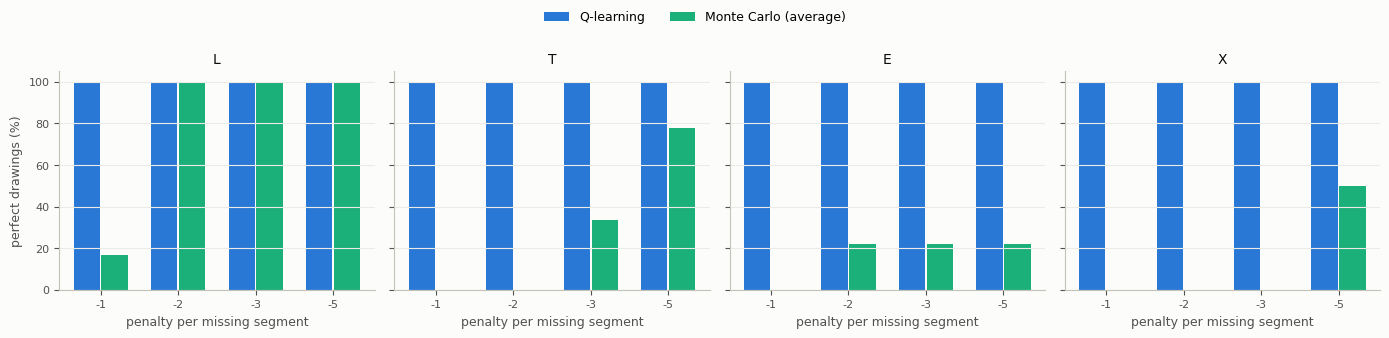

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True, facecolor=SURFACE)
x = np.arange(len(PENALTIES))
for ax, name in zip(axes, EXP1_LETTERS):
    mc = [exp1[(name, p)]["mc_perfect"] * 100 for p in PENALTIES]
    q = [exp1[(name, p)]["q_perfect"] * 100 for p in PENALTIES]
    ax.bar(x - 0.18, q, width=0.34, color="#2a78d6", label="Q-learning")
    ax.bar(x + 0.18, mc, width=0.34, color="#1baf7a", label="Monte Carlo (average)")
    ax.set_xticks(x, [f"{p:g}" for p in PENALTIES])
    style(ax, name, "penalty per missing segment")
axes[0].set_ylabel("perfect drawings (%)", color=MUTED, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig("../results/06_early_stop_penalty.png", dpi=150, facecolor=SURFACE)
plt.show()

## 2. A delayed reward: no +1 per segment

`Rewards(new_segment=0)`: drawing a correct segment gives nothing immediately. The only information about the
quality of the drawing arrives at STOP (+2 if complete, −1 per missing segment). Moves, strokes and segments
outside the letter keep their cost. The optimal drawings have the same length, but the optimal return is now small
(about +1), so we compare the algorithms by the **fraction of perfect drawings** and the **number of episodes
before the first perfect drawing**, rather than by a percentage of the optimum.

Q-learning: 3 runs per letter; SARSA and Monte Carlo: 1 run per letter. **This cell takes about 3 minutes.**

In [5]:
delayed = Rewards(new_segment=0.0)
exp2 = {}
t0 = time.perf_counter()
for name in TRAINING_LETTERS:
    q_runs = [q_learning(LetterWritingEnv(name, rewards=delayed), n_episodes=N_EPISODES, alpha=0.5, gamma=GAMMA, seed=s)
              for s in [0, 1, 2]]
    s_run = sarsa(LetterWritingEnv(name, rewards=delayed), n_episodes=N_EPISODES, alpha=0.1, gamma=GAMMA, seed=0)
    m_run = monte_carlo(LetterWritingEnv(name, rewards=delayed), n_episodes=N_EPISODES, alpha=None, gamma=GAMMA, seed=0)
    for r in q_runs + [s_run, m_run]:
        r.pop("Q")   # the tables are large (up to 28 MB each): keep only the curves
    exp2[name] = {"q": q_runs, "sarsa": s_run, "mc": m_run}
print(f"done ({time.perf_counter() - t0:.0f} s)")

# Shaped reward (README) for comparison: Q-learning from notebook 03, SARSA / MC from notebook 04
with open("../results/03_q_learning_summary.csv") as f:
    shaped_first = {r["letter"]: float(r["episodes_to_first_perfect_median"]) for r in csv.DictReader(f)}
shaped_perfect = {}
with open("../results/04_comparison_summary.csv", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        shaped_perfect[(r["letter"], r["method"])] = float(r["perfect_final"])

print(f"\n{'':<7}{'--------- Q-learning ---------':>40}{'---- SARSA ----':>22}{'---- MC ----':>18}")
print(f"{'letter':<7}{'perfect':>10}{'1st perfect':>14}{'(shaped)':>12}{'perfect':>12}{'(shaped)':>10}{'perfect':>10}{'(shaped)':>10}")
for name in TRAINING_LETTERS:
    e = exp2[name]
    q_perf = np.mean([r["eval_perfect"][-1] for r in e["q"]])
    q_first = np.nanmedian([first_perfect(r) for r in e["q"]]) if any((r["eval_perfect"] == 1).any() for r in e["q"]) else np.nan
    print(f"{name:<7}{q_perf:>10.0%}{(f'{q_first:,.0f}' if not np.isnan(q_first) else '-'):>14}{shaped_first[name]:>12,.0f}"
          f"{e['sarsa']['eval_perfect'][-1]:>12.0%}{shaped_perfect[(name, 'SARSA')]:>10.0%}"
          f"{e['mc']['eval_perfect'][-1]:>10.0%}{shaped_perfect[(name, 'MC (average)')]:>10.0%}")

done (277 s)

                 --------- Q-learning ---------       ---- SARSA ----      ---- MC ----
letter    perfect   1st perfect    (shaped)     perfect  (shaped)   perfect  (shaped)
I            100%        21,000       9,000          0%      100%        0%        0%
L            100%        13,000       5,000        100%      100%        0%       10%
T            100%        21,500       9,500          0%      100%        0%        0%
E              0%             -      10,500          0%      100%        0%        0%
F            100%        23,000       8,000          0%      100%        0%        0%
H              0%             -      12,500          0%      100%        0%        0%
N            100%        26,500       9,000          0%       90%        0%        0%
Z            100%        26,500       9,000          0%      100%        0%        0%
V            100%        17,000       7,000         50%      100%        0%        0%
X            100%        27,000      1

### Learning curves: shaped vs delayed reward (Q-learning)

Fraction of starting points where the greedy policy draws the letter perfectly, during training
(mean over the runs). Shaped = README rewards (notebook 03, 5 runs); delayed = no +1 per segment (3 runs).

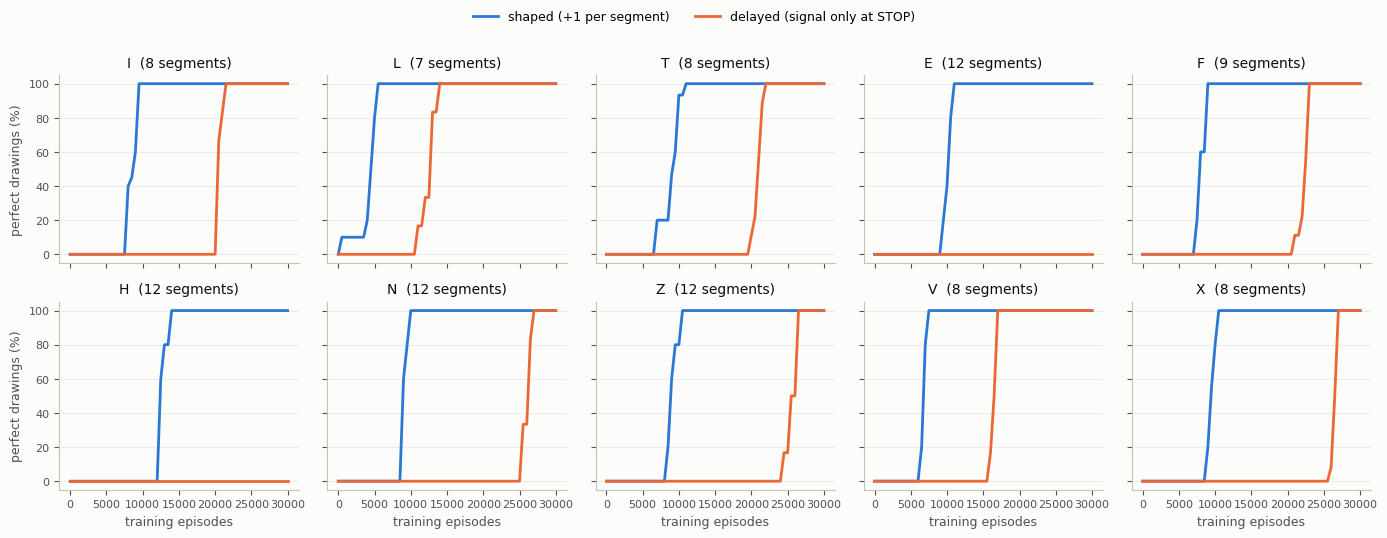

In [6]:
q_curves = np.load("../results/03_q_learning_curves.npz")
episodes = q_curves["episodes"]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4), sharex=True, sharey=True, facecolor=SURFACE)
for ax, name in zip(axes.ravel(), TRAINING_LETTERS):
    shaped = q_curves[f"{name}_perfect"].mean(0) * 100
    late = np.array([r["eval_perfect"] for r in exp2[name]["q"]]).mean(0) * 100
    ax.plot(episodes, shaped, color="#2a78d6", lw=2, label="shaped (+1 per segment)")
    ax.plot(exp2[name]["q"][0]["eval_episodes"], late, color="#eb6834", lw=2, label="delayed (signal only at STOP)")
    ax.set_ylim(-5, 105)
    style(ax, f"{name}  ({LetterWritingEnv(name).k} segments)")
for ax in axes[1]:
    ax.set_xlabel("training episodes", color=MUTED, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("perfect drawings (%)", color=MUTED, fontsize=9)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig("../results/06_delayed_reward.png", dpi=150, facecolor=SURFACE)
plt.show()

## What to notice

(The numbers below come from our test run; yours should be very close, since the seeds are fixed.)

### 1. The early-stop penalty
- **A stronger penalty lets Monte Carlo learn, but slowly and letter by letter.** L is learned perfectly from −2,
  T only at −5 (78 % perfect drawings), X only at −5 (50 %), and E stays partial (22 %) whatever the penalty.
  Q-learning is not affected at all: 96–100 % of the optimum and 100 % perfect drawings for every penalty.
- **The simple prediction gives the right trend, not the exact threshold.** When it predicts "ok", Monte Carlo
  starts to learn in every case; when it predicts "trap", Monte Carlo fails in most cases — but L is learned
  perfectly at −2 and −3 although the trap is predicted. The prediction only compares the two options at the
  very beginning, when the agent plays completely at random; during training ε decreases and the policy
  improves, so the real dynamics are more favourable than this "worst moment" comparison.
- Even without the trap, Monte Carlo remains far less efficient than Q-learning on the long letters (E, X):
  one return per episode, high variance, updates only at the end.

### 2. The delayed reward (no +1 per segment)
- **Q-learning still learns 8 letters out of 10**, perfectly and in every run, but **2 to 3 times more slowly**:
  the first perfect drawing comes after 13,000–27,000 episodes instead of 5,000–12,500 with the shaped reward.
- **It fails on E and H**, the two letters with the longest optimal drawings (15 and 17 steps): the only signal
  comes at the very end, and it must be propagated back over many steps.
- **The curves show when learning happens**: with the delayed reward, the perfect drawings appear late, when ε
  has become small. With strong exploration, random actions (including random STOPs) almost always prevent the
  agent from completing the letter, so it almost never sees the +2. With the shaped reward, every correct
  segment gives a signal, even while exploring a lot.
- **SARSA learns only L (and V in some cases), Monte Carlo nothing**: without intermediate rewards, the noisier
  methods lose almost all their ability to learn.

### For the debate — is reward shaping "cheating"?
The +1 per segment is human knowledge slipped into the reward. Removing it gives a purer problem, but learning
becomes 2–3 times slower for the best method, impossible for the longest letters in our budget, and almost
impossible for SARSA and Monte Carlo. Shaping does not change *what* the agent must achieve here (the optimal
drawings have the same number of steps as with the shaped reward), it changes *how easily* it can discover it — the motivation of Ng, Harada & Russell (1999).
The early-stop penalty shows the other side: a badly chosen value creates a trap that some algorithms
(Monte Carlo) cannot escape, while others (Q-learning) are robust.
